# Fine-Tuning Llama-3.2-3B with QLoRA, Hyperparameter Experiments & Push to HuggingFace

There are **two training runs (Experiment A & B)** with different hyperparameter combinations, comparing the train & eval loss curves to find the best combination without overfitting, then **pushing the best model** (merged 16-bit) to the HuggingFace Hub.

|                | Experiment A | Experiment B |
| -------------- | ------------ | ------------ |
| learning_rate  | 2e-4         | 1e-4         |
| LoRA r / alpha | 16 / 32      | 8 / 16       |
| max_steps      | 800          | 800          |


## Libraries Setup


In [ ]:
import os, re

is_colab = "COLAB_GPU" in os.environ or "COLAB_JUPYTER_TOKEN" in os.environ
is_kaggle = "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if is_colab or is_kaggle:
    import torch

    v = re.match(r"[\d]{1,}\.[\d]{1,}", str(torch.__version__)).group(0)
    xformers = "xformers==" + {
        "2.10": "0.0.34",
        "2.9": "0.0.33.post1",
        "2.8": "0.0.32.post2",
    }.get(v, "0.0.34")

    !pip install sentencepiece protobuf "datasets==4.3.0" "huggingface_hub>=0.34.0" hf_transfer
    !pip install --no-deps unsloth_zoo bitsandbytes accelerate {xformers} peft trl triton unsloth
    !pip install --upgrade "torchao>=0.16.0"
else:
    # Standard local setup
    !pip install unsloth

!pip install transformers==4.56.2
!pip install --no-deps trl==0.22.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 2.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 23.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 6.8 MB/s eta 0:00:00
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: datasets
    Found existing installation: datasets 5.0.0
    Uninstalling datasets-5.0.0:
      Successfully uninstalled datasets-5.0.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.1/81.1 kB 1.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.8/110.8 MB 14.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 61.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 30.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 925.0/925.0 kB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━

In [2]:
import gc
from unsloth import FastLanguageModel
from unsloth.chat_templates import get_chat_template
from trl import SFTTrainer, SFTConfig
import torch
from datasets import load_dataset
import wandb
from transformers import AutoTokenizer, TextStreamer, BitsAndBytesConfig
import matplotlib.pyplot as plt
import pandas as pd
from huggingface_hub import notebook_login, HfApi, create_repo

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


## WandB Setup


In [3]:
USE_WANDB = True
WANDB_PROJECT = "submission"

if USE_WANDB:
    report_target = "wandb"
else:
    os.environ["WANDB_DISABLED"] = "true"
    report_target = "none"

print(f"Logging to: {report_target}")


Logging ke: wandb


## Base Model Configuration (4-bit Quantization)

The base model + LoRA **are reloaded from scratch for every experiment** (see the `run_experiment` function) so that one experiment's configuration does not affect the others.


In [4]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,  # Enable Double Quantization
    bnb_4bit_compute_dtype=torch.float16,  # T4
)

BASE_MODEL = "unsloth/Llama-3.2-3B"


## Dataset Preparation


In [5]:
dataset = load_dataset("Ichsan2895/alpaca-gpt4-indonesian", split="train[:6400]")
print(f"Number of training samples: {len(dataset)}")

README.md: 0.00B [00:00, ?B/s]

alpaca-gpt4-indonesia.csv:   0%|          | 0.00/41.4M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/49969 [00:00<?, ? examples/s]

Number of training samples: 6400


### Unmapped Dataset


In [6]:
dataset[0]

{'Unnamed: 0': 1,
 'input': 'Saranlah slogan untuk kampanye daur ulang\n',
 'output': '1. "Kurangi, gunakan kembali, daur ulang: Bersama untuk masa depan yang lebih hijau."\n2. "Daur ulanglah hari ini, untuk masa depan yang lebih baik."\n3. "Ubah sampahmu menjadi harta karun - Daur ulang!"\n4. "Daur ulang untuk siklus kehidupan."\n5. "Simpan sumber daya, daur ulang lebih banyak."'}

### Mapping Dataset


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
tokenizer = get_chat_template(tokenizer, chat_template="llama-3.2")

system_prompt = "Kamu adalah asisten AI yang membantu menjawab pertanyaan pengguna berdasarkan konteks yang diberikan."


def formatting_prompts_func(examples):
    inputs = examples["input"]
    outputs = examples["output"]
    texts = []

    for user_content, output in zip(inputs, outputs):
        conversation = [
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_content},
            {"role": "assistant", "content": output},
        ]
        text = tokenizer.apply_chat_template(
            conversation, tokenize=False, add_generation_prompt=False
        )
        texts.append(text)
    return {"text": texts}


dataset = dataset.map(formatting_prompts_func, batched=True)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/17.2M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/459 [00:00<?, ?B/s]

Map:   0%|          | 0/6400 [00:00<?, ? examples/s]

In [ ]:
dataset[0]["text"]

'<|begin_of_text|><|start_header_id|>system<|end_header_id|>\n\nCutting Knowledge Date: December 2023\nToday Date: 26 July 2024\n\nKamu adalah asisten AI yang membantu menjawab pertanyaan pengguna berdasarkan konteks yang diberikan.<|eot_id|><|start_header_id|>user<|end_header_id|>\n\nCiptakan cara unik dan lucu untuk menggambarkan presiden negaramu.\n<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\nSebagai AI, saya tidak tergabung dalam satu negara dan karena itu tidak memiliki presiden tertentu yang harus digambarkan. Namun, saya dapat membantu Anda menciptakan deskripsi unik dan lucu tentang presiden negara Anda jika Anda memberikan informasi lebih lanjut!<|eot_id|>'

### Split Dataset


In [9]:
dataset = dataset.train_test_split(test_size=0.1, seed=42)
train_dataset = dataset["train"]
eval_dataset = dataset["test"]

eval_dataset = eval_dataset.select(range(100))

## Supervised Fine-Tuning with Two Hyperparameter Experiments

The two experiments are run with **identical data & splits** (seed 42) so the comparison is fair. Each experiment reloads the base model + a fresh LoRA from scratch, saves its adapter locally, then clears VRAM before the next experiment.

The best checkpoint of each experiment is selected automatically based on the **lowest eval_loss** (`load_best_model_at_end`), so what gets saved is not the final step, which may be overfitted.


In [10]:
EXPERIMENTS = [
    {
        "name": "exp_A",
        "learning_rate": 2e-4,
        "lora_r": 16,
        "lora_alpha": 32,
        "max_steps": 800,
    },
    {
        "name": "exp_B",
        "learning_rate": 1e-4,
        "lora_r": 8,
        "lora_alpha": 16,
        "max_steps": 800,
    },
]

EXPERIMENTS


[{'name': 'exp_A',
  'learning_rate': 0.0002,
  'lora_r': 16,
  'lora_alpha': 32,
  'max_steps': 800},
 {'name': 'exp_B',
  'learning_rate': 0.0001,
  'lora_r': 8,
  'lora_alpha': 16,
  'max_steps': 800}]

In [11]:
def run_experiment(cfg):
    name = cfg["name"]
    print("=" * 60)
    print(f"Starting experiment: {name} -> {cfg}")
    print("=" * 60)

    for var in ("model", "trainer"):
        if var in globals():
            del globals()[var]
    gc.collect()
    torch.cuda.empty_cache()

    if USE_WANDB:
        wandb.init(project=WANDB_PROJECT, name=name, config=cfg)

    model, tokenizer = FastLanguageModel.from_pretrained(
        model_name=BASE_MODEL,
        max_seq_length=256,
        quantization_config=bnb_config,
        full_finetuning=False,
        dtype=None,
    )
    tokenizer = get_chat_template(tokenizer, chat_template="llama-3.2")

    model = FastLanguageModel.get_peft_model(
        model,
        target_modules=[
            "q_proj",
            "k_proj",
            "v_proj",
            "o_proj",
            "gate_proj",
            "up_proj",
            "down_proj",
        ],
        r=cfg["lora_r"],
        lora_alpha=cfg["lora_alpha"],
        lora_dropout=0,
        bias="none",
        use_gradient_checkpointing="unsloth",
    )

    sft_config = SFTConfig(
        output_dir=f"outputs_{name}",
        per_device_train_batch_size=4,
        gradient_accumulation_steps=2,
        warmup_steps=5,
        max_steps=cfg["max_steps"],
        learning_rate=cfg["learning_rate"],
        lr_scheduler_type="linear",
        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(),
        logging_steps=1,
        eval_strategy="steps",
        eval_steps=400,
        save_strategy="steps",
        save_steps=400,
        save_total_limit=1,
        per_device_eval_batch_size=4,
        optim="paged_adamw_8bit",
        dataset_text_field="text",
        max_seq_length=256,
        packing=True,
        report_to=report_target,
        run_name=name,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        seed=42,
    )

    trainer = SFTTrainer(
        model=model,
        processing_class=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        args=sft_config,
    )
    trainer.model.print_trainable_parameters()
    trainer.train()

    log_history = trainer.state.log_history
    train_curve = [
        (int(h["step"]), float(h["loss"])) for h in log_history if "loss" in h
    ]
    eval_curve = [
        (int(h["step"]), float(h["eval_loss"])) for h in log_history if "eval_loss" in h
    ]

    best_step, best_eval_loss = min(eval_curve, key=lambda x: x[1])
    final_eval_loss = eval_curve[-1][1]
    last_train_loss = train_curve[-1][1]

    adapter_dir = os.path.join("adapters", name)
    trainer.model.save_pretrained(adapter_dir)
    tokenizer.save_pretrained(adapter_dir)

    result = {
        "name": name,
        "config": cfg,
        "train_curve": train_curve,
        "eval_curve": eval_curve,
        "best_step": best_step,
        "best_eval_loss": best_eval_loss,
        "final_eval_loss": final_eval_loss,
        "last_train_loss": last_train_loss,
        "eval_gap": final_eval_loss - last_train_loss,
        "overfit_trend": final_eval_loss > best_eval_loss,
        "adapter_dir": adapter_dir,
    }

    print(
        f"[{name}] best eval_loss={best_eval_loss:.4f} @ step {best_step} | "
        f"final eval_loss={final_eval_loss:.4f} | adapter saved to {adapter_dir}"
    )

    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    if USE_WANDB:
        wandb.finish()

    return result


In [ ]:
results = []

for cfg in EXPERIMENTS:
    results.append(run_experiment(cfg))

print("Done. Experiments run:", [r["name"] for r in results])

Starting experiment: exp_A -> {'name': 'exp_A', 'learning_rate': 0.0002, 'lora_r': 16, 'lora_alpha': 32, 'max_steps': 800}


wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

  2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter:

  ········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: catastrophically21 (catastrophically21-personal) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


... (24 outputs left out)

Step,Training Loss,Validation Loss
400,1.144800,1.231243
800,1.134700,1.216195


[exp_B] best eval_loss=1.2162 @ step 800 | final eval_loss=1.2162 | adapter saved to adapters/exp_B


eval/loss,█▁
eval/runtime,▁█
eval/samples_per_second,█▁
eval/steps_per_second,█▁
train/epoch,▁▁▁▁▁▁▂▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▅▅▆▆▆▆▆▇▇▇▇▇▇▇██
train/global_step,▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▄▅▅▅▆▆▆▇▇▇▇▇▇███
train/grad_norm,▆█▂▂▂▁▂▂▃▂▃▂▄▂▃▂▂▃▃▁▂▂▃▃▂▂▃▁▃▂▃▃▃▂▃▂▃▂▂▃
train/learning_rate,████▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▄▄▄▄▃▃▃▃▃▃▂▂▁▁▁
train/loss,█▇▅▄▃▂▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▂▂▂▂▂▂▂▂▁▁▂▁▂▂▁▂▂
eval/loss,1.21619
eval/runtime,15.3472


Done. Experiments run: ['exp_A', 'exp_B']


## Loss Curve Comparison

The **train loss** (solid line) and **eval loss** (dashed line) curves of each experiment. The star marks the best eval loss point. An eval loss that rises again at the end of training is a sign of **overfitting**.


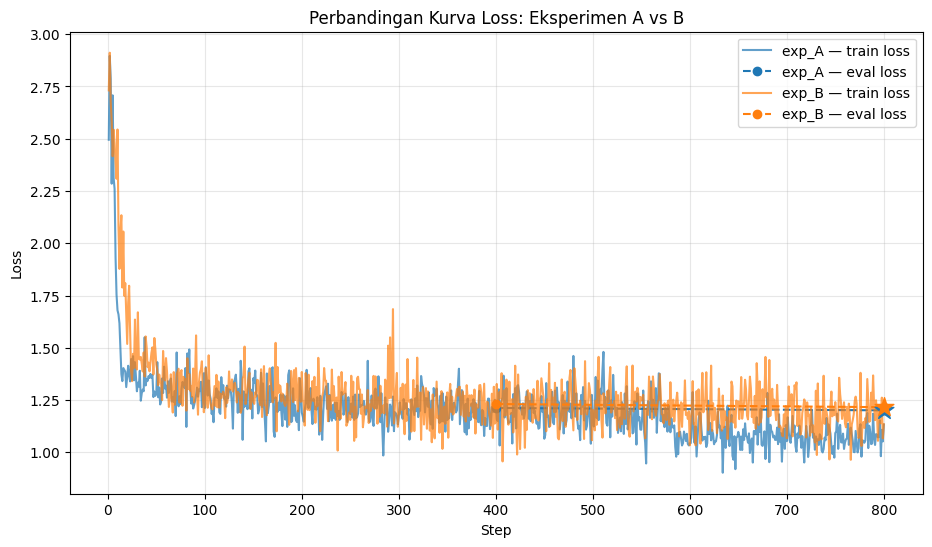

In [13]:
COLORS = {"exp_A": "tab:blue", "exp_B": "tab:orange"}

fig, ax = plt.subplots(figsize=(11, 6))

for r in results:
    c = COLORS[r["name"]]
    tr_steps, tr_loss = zip(*r["train_curve"])
    ev_steps, ev_loss = zip(*r["eval_curve"])

    ax.plot(
        tr_steps,
        tr_loss,
        color=c,
        linestyle="-",
        alpha=0.7,
        label=f"{r['name']} — train loss",
    )
    ax.plot(
        ev_steps,
        ev_loss,
        color=c,
        linestyle="--",
        marker="o",
        label=f"{r['name']} — eval loss",
    )

    best_i = min(range(len(ev_loss)), key=lambda i: ev_loss[i])
    ax.scatter(ev_steps[best_i], ev_loss[best_i], color=c, marker="*", s=200, zorder=5)

ax.set_xlabel("Step")
ax.set_ylabel("Loss")
ax.set_title("Loss Curve Comparison: Experiment A vs B")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


## Selecting the Best Experiment

The best experiment is selected automatically based on the **best (lowest) eval_loss**, with the overfitting trend (eval loss rising at the end) and the train-eval gap as additional indicators.


In [14]:
summary = pd.DataFrame(
    [
        {
            "experiment": r["name"],
            "learning_rate": r["config"]["learning_rate"],
            "lora_r": r["config"]["lora_r"],
            "max_steps": r["config"]["max_steps"],
            "best_eval_loss": round(r["best_eval_loss"], 4),
            "final_eval_loss": round(r["final_eval_loss"], 4),
            "last_train_loss": round(r["last_train_loss"], 4),
            "gap_eval_train": round(r["eval_gap"], 4),
            "overfit_trend": r["overfit_trend"],
        }
        for r in results
    ]
)
display(summary)

best_result = min(results, key=lambda r: (r["best_eval_loss"], r["overfit_trend"]))
print(
    f"Best experiment: {best_result['name']} (best eval_loss={best_result['best_eval_loss']:.4f})"
)


,experiment,learning_rate,lora_r,max_steps,best_eval_loss,final_eval_loss,last_train_loss,gap_eval_train,overfit_trend
0,exp_A,0.0002,16,800,1.2011,1.2011,1.1328,0.0683,False
1,exp_B,0.0001,8,800,1.2162,1.2162,1.1347,0.0815,False


Best experiment: exp_A (best eval_loss=1.2011)


### Reloading the Best Model


In [15]:
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=best_result["adapter_dir"],
    max_seq_length=256,
    quantization_config=bnb_config,
    full_finetuning=False,
    dtype=None,
)
tokenizer = get_chat_template(tokenizer, chat_template="llama-3.2")


==((====))==  Unsloth 2026.9.11: Fast Llama patching. Transformers: 4.56.2.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.34. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
total weights      : 2.335 GiB
no_split classes   : ['LlamaDecoderLayer']
output head        : lm_head -> cuda:1
head headroom      : 0.342 GiB
activation reserve : 10.727 GiB requested
tied to head       : ['model.embed_tokens']
  cuda:0  budget  12.73 GiB  weights  1.418 GiB  free 11.307 GiB  reserve 10.727 GiB
  cuda:1  budget  11.41 GiB  weights  0.917 GiB  free 10.488 GiB  reserve  9.960 GiB   <- output head
note: Bnb4BitHfQuantizer.adjust_max_memory lowered the budget on cuda:0 14.139 -> 12.726 GiB, cuda:1 12.673 -> 11.405 GiB (memory t

## Push the Best Model to HuggingFace

Log in manually to HuggingFace (requires a token with **write** access), then the best model is pushed in **merged 16-bit** form so it can be used directly for inference.

Set `HF_REPO_NAME` and `HF_PRIVATE` before running if needed.


In [16]:
notebook_login()

In [18]:
HUGGINGFACE_USERNAME = None
HF_REPO_NAME = "llama-3.2-3b-sft-indonesian"
HF_PRIVATE = False

api = HfApi()
if HUGGINGFACE_USERNAME is None:
    HUGGINGFACE_USERNAME = api.whoami()["name"]

repo_id = f"{HUGGINGFACE_USERNAME}/{HF_REPO_NAME}"
create_repo(repo_id, private=HF_PRIVATE, exist_ok=True)

model.push_to_hub_merged(repo_id, tokenizer=tokenizer, save_method="merged_16bit")

model_url = f"https://huggingface.co/{repo_id}"
print(f"Best model ({best_result['name']}) pushed to: {model_url}")
print("Paste the link above into link_huggingface.txt")


config.json:   0%|          | 0.00/890 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model-00001-of-00002.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Preparing safetensor model files:   0%|          | 0/2 [00:00<?, ?it/s]

... (9 outputs left out)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [02:35<00:00, 77.67s/it] 


Unsloth: Merge process complete. Saved to `/kaggle/working/m-b-edw/llama-3.2-3b-sft-indonesian`
Best model (exp_A) pushed to: https://huggingface.co/m-b-edw/llama-3.2-3b-sft-indonesian
Paste the link above into link_huggingface.txt


## Test Inference Best Model


In [19]:
FastLanguageModel.for_inference(model)

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): LlamaForCausalLM(
      (model): LlamaModel(
        (embed_tokens): Embedding(128256, 3072, padding_idx=128004)
        (layers): ModuleList(
          (0): LlamaDecoderLayer(
            (self_attn): LlamaAttention(
              (q_proj): lora.Linear4bit(
                (base_layer): Linear4bit(in_features=3072, out_features=3072, bias=False)
                (lora_dropout): ModuleDict(
                  (default): Identity()
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=3072, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=3072, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
              (k_proj): lora.Linear

In [20]:
messages = [
    {
        "role": "system",
        "content": "Anda adalah asisten cerdas yang menjawab pertanyaan secara akurat berdasarkan fakta.",
    },
    {
        "role": "user",
        "content": "Jelaskan UU tenaga kerja secara singkat.",
    },
]


inputs = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_tensors="pt",
).to("cuda")

In [22]:
text_streamer = TextStreamer(tokenizer, skip_prompt=True)

_ = model.generate(
    input_ids=inputs,
    streamer=text_streamer,
    max_new_tokens=256,
    temperature=0.3,
    repetition_penalty=1.2,
    do_sample=True,
    eos_token_id=tokenizer.eos_token_id,
    pad_token_id=tokenizer.eos_token_id,
)

Undang-undang Tenaga Kerja (ELA) adalah undang-undang federal Amerika Serikat yang mengatur hubungan antara pekerja dan karyawan, serta menetapkan hak-hak dan kewajiban mereka. ELA memberikan perlindungan terhadap diskriminasi dalam hal gaji, layanan, dan keadaan kerja lainnya, termasuk pengambilalihan pekerjaan, pemecatan tanpa alasan, dan pembayaran kompensasi atas waktu tidak bekerja.

Selain itu, ELA juga mempromosikan kesepahaman dan kolaborasi antara manajemen dan pekerjaaan melalui perjanjian kolektif, di mana seringkali disebut sebagai kontrak kerja. Kontrak-kontrak ini dapat mencakup kondisi kerja seperti jam kerja, upah minimum, cuti, dan hari libur. Selain itu, ELA menyediakan regulasi untuk insentif pemberhentian dan retribusi pelepasan pekerja dari tugas tertentu atau tempat kerja.

ELA telah diperbarui beberapa kali sepanjang sejarah
